# *Pipeline replicated for project*



In [ ]:
import os
import mne
import numpy as np
import matplotlib.pyplot as plt  # for graphs 

# GLOBAL VARIABLES
data_dir = r'C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data' # Keep your actual root folder here
subject = 'CA103'
session = '1'
task = 'dur'
run = '05'
suffix = 'raw_sss' # new suffix for the processed file after Maxwell filtering

# Add your specific file extension (assuming .fif based on previous steps)
extension = '.fif' 

# (f-string): Replaces variable names in curly braces with their values
# BUILD THE FOLDER PATH
subject_folder = f'sub-{subject}' 
session_folder = f'ses-{session}'
folder_path = os.path.join(data_dir, subject_folder, session_folder, 'derivatives')

# BUILD THE FILE NAME
# This will now construct: sub-CA103_ses-1_task-dur_run-01_meg.fif
file_name = f'sub-{subject}_ses-{session}_task-{task}_run-{run}_{suffix}{extension}'
raw_file_path = os.path.join(folder_path, file_name) 

# VERIFY AND LOAD
print(f"Attempting to load: {raw_file_path}")

# A safety guard. If the file is missing, it stops immediately
if not os.path.exists(raw_file_path):
    raise FileNotFoundError("The file was not found. Check the path.")

# Load only the single run into RAM
raw = mne.io.read_raw_fif(raw_file_path, preload=True) 

Attempting to load: C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_raw_sss.fif
Opening raw data file C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_raw_sss.fif...
    Range : 37000 ... 842999 =     37.000 ...   842.999 secs
Ready.
Reading 0 ... 805999  =      0.000 ...   805.999 secs...


In [30]:
# SETUP EXPORT PATHS FOR MAX FILTER AND ANNOTATIONS
# We will create a 'derivatives' folder inside your subject's folder 
# to keep your processed files separate from your raw data.

derivatives_dir = os.path.join(data_dir, subject_folder, session_folder, 'derivatives')

# Create this folder on your hard drive if it doesn't exist yet
if not os.path.exists(derivatives_dir):
    os.makedirs(derivatives_dir)


# Build the file names for the annotations using f-strings
# We replace the 'meg' suffix with 'ann' (annotations)
ann_file_name_fif = f'sub-{subject}_ses-{session}_task-{task}_run-{run}_ann.fif'
ann_file_name_csv = f'sub-{subject}_ses-{session}_task-{task}_run-{run}_ann.csv'

# Combine the folder path and file names
ann_file_path_fif = os.path.join(derivatives_dir, ann_file_name_fif)
ann_file_path_csv = os.path.join(derivatives_dir, ann_file_name_csv)

print(f"FIF export path: {ann_file_path_fif}")
print(f"CSV export path: {ann_file_path_csv}")

FIF export path: C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif
CSV export path: C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.csv


## Identifying eye blinks

Here we show how the artefacts associated with eye blinks can be marked automatically on the basis of the vertical EOG channel (EOG001 in our case). After bandpass filtering the EOG signal between 1 - 10 Hz, the threshold for blink detection is determined according to:

$$ (max(vEOG) - min(vEOG)) / 4 $$

 Segments being 500 ms long starting 250 ms prior to exceeding the threshold are annotated as blinks. 

In [ ]:
# EYE BLINK (EOG) ANNOTATION ---

# MNE scans the data for huge, sudden spikes typical of eye blinks.
# It outputs an array (a grid of numbers) containing the timestamp of every blink peak.
eog_events = mne.preprocessing.find_eog_events(raw, ch_name='EOG001')
# isolate EOG -> band filter 1-10Hz -> peak-to-peak threshold formula -> find peaks -> return timestamps of peaks
# output is SAMPLE INDEX of blinks- A 2D array where column 0 stores the sample index of every blink peak found

# CREATE THE BLINK "STICKY NOTES" 
n_blinks = len(eog_events) # Count how many total blinks were found

# MATH EXPLANATION BELOW
onset = eog_events[:, 0] / raw.info['sfreq'] - 0.25
# onset is defined as sample index divided by the sampling frequency (sfreq) to convert it to seconds, minus 0.25 seconds to shift the onset time slightly earlier than the actual peak.

# Create a list saying every blink lasts exactly 0.5 seconds
duration = np.repeat(0.5, n_blinks)
# Sets every blink note to cover a full 0.5-second window (250 ms before the peak +250 ms after the peak).

# Labels every one of the intervals with the text 'blink'
# Create a list of labels that just says the word 'blink' over and over
description = ['blink'] * n_blinks


# Synchronizes the clock with the exact date and microsecond when the MEG scanner started recording.
orig_time = raw.info['meas_date']

# Package all of these lists together into official MNE "Annotations" (digital sticky notes)
annotations_blink = mne.Annotations(onset, duration, description, orig_time)

Using EOG channel: EOG001
EOG channel index for this subject is: [0]
Filtering the data to remove DC offset to help distinguish blinks from saccades
Selecting channel EOG001 for blink detection
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 10000 samples (10.000 s)

Now detecting blinks and generating corresponding events
Found 1198 significant peaks
Number of EOG events detected: 1198


## Finding muscle artefacts

Muscle artefacts are identified from the magnetometer data filtered in the 110 - 140 Hz range. The data are subsequently z-scored. If they exceed the value *threshold_muscle*, the corresponding section of data is annotated as muscle artifact. The shortest allowed duration of non-annotated data is 0.2 s; shorter segments will be incorporated into the surrounding annotations.

What is a Z-score?
A Z-score measures: "How many standard deviations is this value away from the normal average?" 
z=x−μ/σ

z=0: Completely average baseline.
z=2/3: Slightly elevated.
z=10.0: A massive spike that is 10 times higher than the baseline noise level. Setting threshold_muscle = 10.0 ensures we only catch genuine, hard jaw clenches or swallows, without accidentally flagging normal resting brain noise.

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1.1e+02 - 1.4e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 110.00
- Lower transition bandwidth: 27.50 Hz (-6 dB cutoff frequency: 96.25 Hz)
- Upper passband edge: 140.00 Hz
- Upper transition bandwidth: 35.00 Hz (-6 dB cutoff frequency: 157.50 Hz)
- Filter length: 121 samples (0.121 s)

Setting up low-pass filter at 4 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Upper passband edge: 4.00 Hz
- Upper transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 5.00 Hz)
- Filter length: 1651 samples (1.651 s)



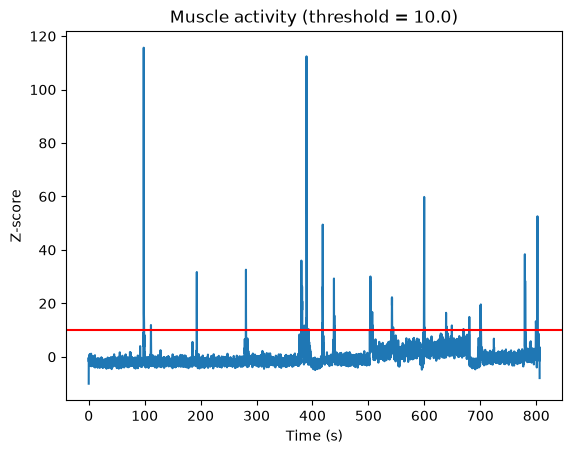

In [ ]:
from mne.preprocessing import annotate_muscle_zscore # specialized MNE algorithm that calculates how "loud" muscle frequencies are.

# MUSCLE ARTIFACT DETECTION & VISUALIZATION
# it is only marked here, not removed yet. 

# RUN THE DETECTION
# A threshold of 10 is quite high. It means a spike has to be 
# 10 standard deviations louder than the baseline to be flagged as a muscle artifact.
threshold_muscle = 10.0  

# Envelope extraction (Hilbert transform): Calculates instantaneous power/amplitude of that high-frequency noise across time.
annotations_muscle, scores_muscle = annotate_muscle_zscore( # scores_muscle: The continuous Z-score curve across time (used for plotting).
    raw, 
    ch_type="mag", # Uses only the 102 magnetometers (they have wide spatial coverage sensitive to neck and temporalis muscles).
    threshold=threshold_muscle, 
    min_length_good=0.2, # two muscle spasms 0.15 seconds apart, the brain signal is unusable --> merges them into one continuous artifact block.
    filter_freq=[110, 140] # using a zero-phase bandpass filter
)

# 2. PLOT THE RESULTS
fig1, ax = plt.subplots()

# Draw the blue line representing the continuous muscle noise level
ax.plot(raw.times, scores_muscle)

# Draw the red horizontal line representing your threshold of 10
ax.axhline(y=threshold_muscle, color='r')

# Add labels
ax.set(xlabel='Time (s)', 
       ylabel='Z-score', 
       title=f'Muscle activity (threshold = {threshold_muscle})')

# Command to actually display the plot in a standard Python script
plt.show()

## Include annotations in dataset and inspect

Now mark all the annotations in the data set.


*Calling set_annotations() replaces any annotations currently stored in the Raw object. To prevent that, we first extract their annotations and then combine them together with the blink and muscle annotations*.

In [33]:
annotations_event = raw.annotations 
raw.set_annotations(annotations_event + annotations_blink + annotations_muscle)

C:\Users\manju\AppData\Local\Temp\ipykernel_8168\3531103679.py:2: RuntimeWarning: Limited 2 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations_event + annotations_blink + annotations_muscle)


<Raw | sub-CA103_ses-1_task-dur_run-05_raw_sss.fif, 341 x 806000 (806.0 s), ~2.05 GiB, data loaded>

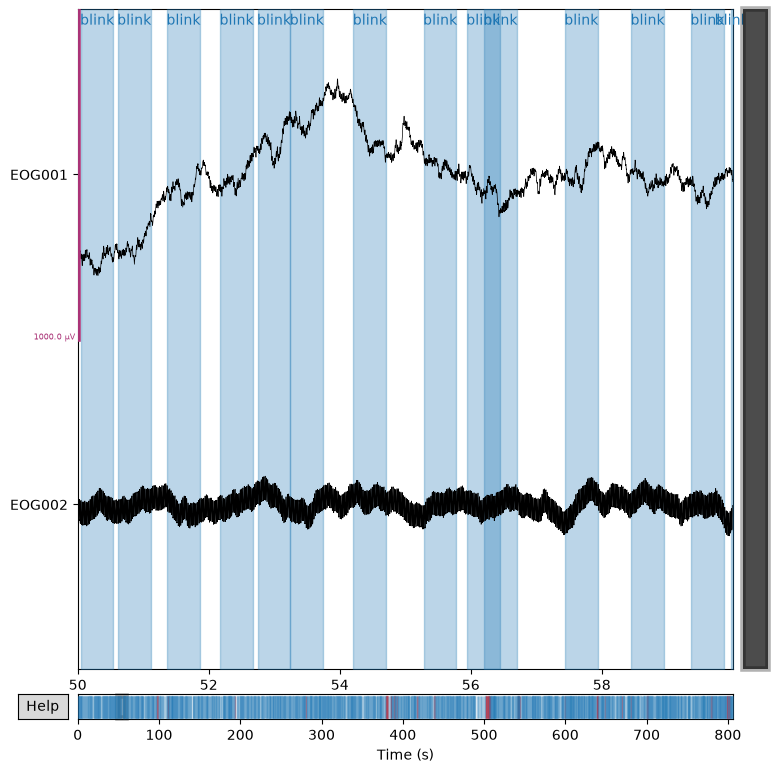

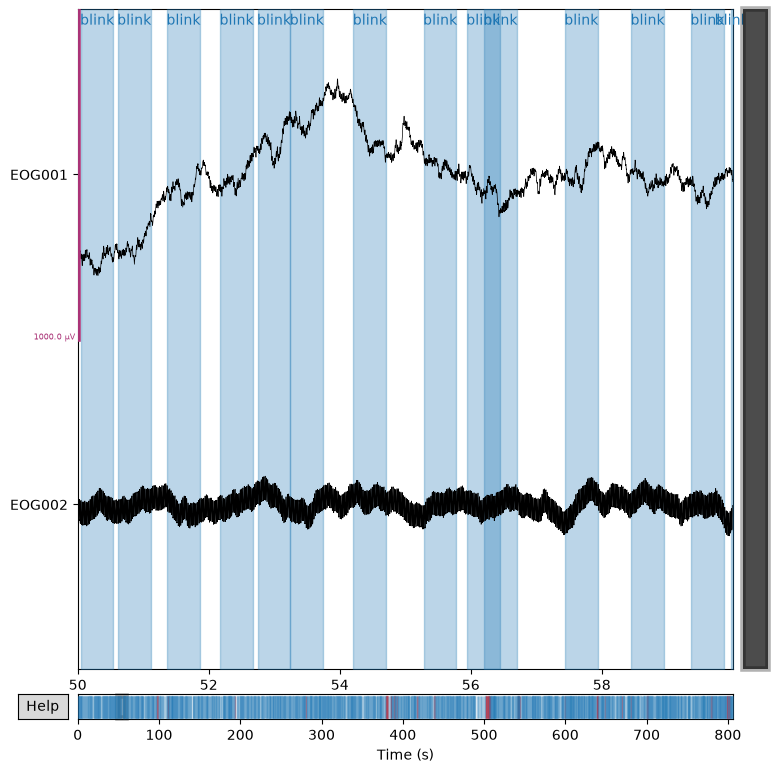

In [ ]:
# CONFIGURING AND VIEWING EYE BLINK CHANNELS (EOG)

# Optional: Print all channel names just in case you need to find the real EOG names
# print(raw.ch_names) 

# 1. DEFINE THE CHANNEL TYPES
# Tell MNE that these specific channels are tracking eye movements (EOG)
# Note: If your scanner named them differently (e.g., 'EOG061' or 'EXG1'), 
# you must change the names in the quotes below to match your real data.
raw.set_channel_types({
    'EOG001': 'eog',
    'EOG002': 'eog'
})

# 2. SELECT THE CHANNELS
# Create an array that points only to the EOG channels, ignoring all the MEG brain sensors
eog_picks = mne.pick_types(raw.info, meg=False, eog=True)
# Filters your view so it displays only the EOG channels, hiding the 306 brain channels

# 3. SET THE VISUAL ZOOM (SCALING)
# EOG voltages are much larger than MEG magnetic fields. 
# We set the scale to 500 microvolts (500e-6) so the graph isn't too huge.
scl = dict(eog=500e-6)

# 4. PLOT THE DATA
# Open the viewer at 50 seconds, specifically sorting the EOG channels to the top
raw.plot(order=eog_picks, scalings=scl, start=50.0, duration=10.0)

In [35]:
# --- 10. COMBINING AND SAVING THE DATA ---
# 1. ATTACH THE ANNOTATIONS (preserving the experimental trigger events)
raw.set_annotations(annotations_event + annotations_blink + annotations_muscle)
# 2. SAVE THE DATA
raw.save(ann_file_path_fif, overwrite=True)
# 3. EXPORT A BACKUP
raw.annotations.save(ann_file_path_csv, overwrite=True)
print(f"Successfully saved Run {run} data to: {ann_file_path_fif}")

Writing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_8168\3065327737.py:3: RuntimeWarning: Limited 2 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations_event + annotations_blink + annotations_muscle)
C:\Users\manju\AppData\Local\Temp\ipykernel_8168\3065327737.py:5: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(ann_file_path_fif, overwrite=True)


Closing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif
[done]
Successfully saved Run 05 data to: C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif
